# Tugas UTS Machine Learning

**Nama:** Muhamad Fatir  
**NIM:** 241011402714  
**Kelas:** Reg B  
**Angka acak:** 14

Notebook ini memakai data untuk menjawab dua pertanyaan sederhana: apakah biaya iklan berkaitan dengan penjualan, dan seberapa mungkin sebuah email adalah spam? Bagian utama menghitung jawabannya dengan NumPy. Bagian bonus membandingkannya dengan scikit-learn. Simpan kedua file CSV bersama notebook agar data mudah ditemukan.

## 1. Isi Tugas dan Pemeriksaan Data

Tugas ini punya tiga bagian: **A** memperkirakan penjualan dari biaya iklan, **B** menilai email spam, dan **C** menjawab pertanyaan konsep. Ada juga bonus untuk membandingkan hasil dengan scikit-learn.

Program memeriksa nama kolom, jumlah baris, dan apakah ada data kosong. Hasil hitungannya muncul setelah sel dijalankan; angka tidak diisi sebelumnya.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 14


def find_data_directory():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "Ads_Data.csv").is_file() and (directory / "Email_Data.csv").is_file():
            return directory
    raise FileNotFoundError(
        "Ads_Data.csv and Email_Data.csv must be in the notebook directory or one of its parents."
    )


def train_test_split_numpy(X, y, test_size, random_state):
    X = np.asarray(X)
    y = np.asarray(y)
    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1.")
    test_count = int(round(len(X) * test_size))
    indices = np.random.RandomState(random_state).permutation(len(X))
    test_indices = indices[:test_count]
    train_indices = indices[test_count:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]


def regression_metrics(y_true, y_pred):
    residuals = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    mse = float(np.mean(residuals ** 2))
    total_sum_squares = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r_squared = 1 - float(np.sum(residuals ** 2)) / total_sum_squares
    return {
        "MAE": float(np.mean(np.abs(residuals))),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "R2": r_squared,
    }


def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    accuracy = (tp + tn) / len(y_true) if len(y_true) else 0.0
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return np.array([[tn, fp], [fn, tp]]), {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


data_dir = find_data_directory()
ads_data = pd.read_csv(data_dir / "Ads_Data.csv")
email_data = pd.read_csv(data_dir / "Email_Data.csv")
assert list(ads_data.columns) == ["BiayaIklan", "Penjualan"]
assert list(email_data.columns) == ["JumlahLink", "KataPromo", "Spam"]
assert not ads_data.isna().any().any() and not email_data.isna().any().any()
assert set(email_data["Spam"].unique()).issubset({0, 1})

print(f"Direktori data ditemukan relatif terhadap notebook: {data_dir}")
print(f"Ads_Data.csv: {ads_data.shape[0]} baris, kolom {ads_data.columns.tolist()}")
print(f"Email_Data.csv: {email_data.shape[0]} baris, kolom {email_data.columns.tolist()}")
print("Pemeriksaan kolom, nilai kosong, dan label biner: lulus.")

Direktori data ditemukan relatif terhadap notebook: c:\Users\T480G8\OneDrive\Documents\tugas2
Ads_Data.csv: 40 baris, kolom ['BiayaIklan', 'Penjualan']
Email_Data.csv: 60 baris, kolom ['JumlahLink', 'KataPromo', 'Spam']
Pemeriksaan kolom, nilai kosong, dan label biner: lulus.


## 2. Bagian A: Memperkirakan Penjualan

Data iklan berisi biaya iklan dan penjualan tiap bulan. Program memakai biaya iklan untuk memperkirakan penjualan dengan sebuah garis lurus. Sebanyak 32 baris dipakai untuk membuat garis, dan 8 baris disisihkan untuk mengujinya.

Angka `intercept` adalah perkiraan penjualan saat biaya iklan 0. Angka `koefisien` menunjukkan perubahan perkiraan penjualan untuk setiap tambahan biaya iklan Rp1 juta. Data uji tidak dipakai saat membuat garis, agar pengujian memakai data yang belum dilihat model.

A1: 5 baris pertama


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah data: 40; bentuk X: (40, 1); bentuk y: (40,)


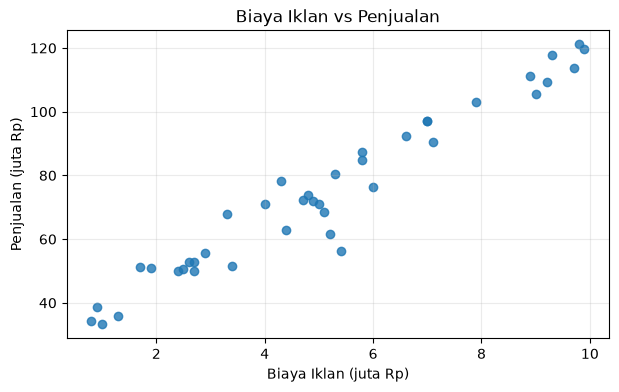

A2: X_train=(32, 1), X_test=(8, 1), y_train=(32,), y_test=(8,)
A3: intercept (b) = 29.145637
A3: koefisien (m) = 8.855992
Persamaan: y_hat = 29.145637 + 8.855992 * BiayaIklan
Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan perubahan prediksi penjualan sebesar 8.856 juta Rp secara linear.


In [2]:
# A1: data, fitur dua dimensi, dan visualisasi
X_ads = ads_data[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = ads_data["Penjualan"].to_numpy(dtype=float)
print("A1: 5 baris pertama")
display(ads_data.head())
print(f"Jumlah data: {len(ads_data)}; bentuk X: {X_ads.shape}; bentuk y: {y_ads.shape}")

plt.figure(figsize=(7, 4))
plt.scatter(X_ads[:, 0], y_ads, alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()

# A2: split dilakukan sebelum fitting agar data test tidak bocor ke model.
X_ads_train, X_ads_test, y_ads_train, y_ads_test = train_test_split_numpy(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print(f"A2: X_train={X_ads_train.shape}, X_test={X_ads_test.shape}, "
      f"y_train={y_ads_train.shape}, y_test={y_ads_test.shape}")

# A3: Normal Equation NumPy, dengan kolom bias eksplisit.
X_ads_design = np.column_stack([np.ones(len(X_ads_train)), X_ads_train])
ads_parameters = np.linalg.pinv(X_ads_design) @ y_ads_train
ads_intercept = float(ads_parameters[0])
ads_slope = float(ads_parameters[1])

print(f"A3: intercept (b) = {ads_intercept:.6f}")
print(f"A3: koefisien (m) = {ads_slope:.6f}")
print(f"Persamaan: y_hat = {ads_intercept:.6f} + {ads_slope:.6f} * BiayaIklan")
print(f"Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan perubahan "
      f"prediksi penjualan sebesar {ads_slope:.3f} juta Rp secara linear.")

## 3. Bagian B: Menilai Email Spam

Setiap email punya dua ciri pada data ini: jumlah tautan dan jumlah kata promosi. Label `Spam` bernilai 1 untuk spam dan 0 untuk bukan spam. Program belajar dari 45 email, lalu menguji perkiraannya pada 15 email yang disisihkan.

Agar kedua ciri punya skala yang sebanding, program menghitung rata-rata dan sebaran angka dari data belajar saja. Data uji tidak ikut dipakai saat menyiapkan model.

B1: 5 email pertama


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64


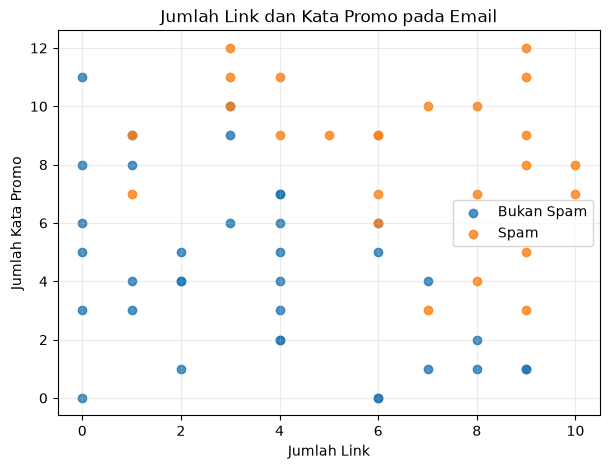

B2: bentuk X_train=(45, 2), X_test=(15, 2); y_train=(45,), y_test=(15,)
Learning rate=0.1, iterasi=10000
Intercept (skala asli)=-9.446247
Koefisien (JumlahLink, KataPromo)=[0.81478498 0.80980187]
P(Spam) = sigmoid(-9.446247 + 0.814785*JumlahLink + 0.809802*KataPromo)


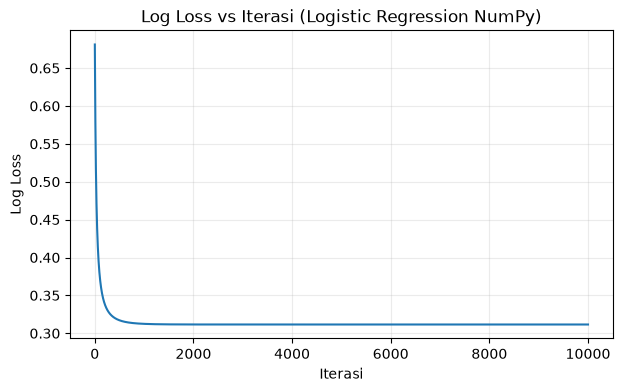

Log loss turun dari 0.681106 menjadi 0.311602.
Pada 500 putaran terakhir, loss berada antara 0.311602 hingga 0.311602.


In [3]:
# B1: kelas, dua fitur, dan visualisasi.
X_email = email_data[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_data["Spam"].to_numpy(dtype=int)
print("B1: 5 email pertama")
display(email_data.head())
print("Jumlah kelas:")
print(email_data["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam", 1: "Spam"}))

plt.figure(figsize=(7, 5))
for label, name, color in [(0, "Bukan Spam", "tab:blue"), (1, "Spam", "tab:orange")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, alpha=0.8, color=color)
plt.title("Jumlah Link dan Kata Promo pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# B2: split sebelum menghitung parameter standardisasi atau melatih model.
X_email_train, X_email_test, y_email_train, y_email_test = train_test_split_numpy(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
email_mean = X_email_train.mean(axis=0)
email_scale = X_email_train.std(axis=0)
email_scale[email_scale == 0] = 1.0
X_email_train_scaled = (X_email_train - email_mean) / email_scale
X_email_test_scaled = (X_email_test - email_mean) / email_scale


def sigmoid(logits):
    return 1.0 / (1.0 + np.exp(-np.clip(logits, -500, 500)))


def logistic_log_loss_from_logits(y_true, logits):
    return float(np.mean(np.logaddexp(0, logits) - y_true * logits))


logistic_weights = np.zeros(X_email_train_scaled.shape[1], dtype=float)
logistic_bias = 0.0
logistic_learning_rate = 0.1
logistic_iterations = 10_000
logistic_loss_history = []
for _ in range(logistic_iterations):
    logits = X_email_train_scaled @ logistic_weights + logistic_bias
    probabilities = sigmoid(logits)
    errors = probabilities - y_email_train
    logistic_weights -= logistic_learning_rate * (X_email_train_scaled.T @ errors) / len(y_email_train)
    logistic_bias -= logistic_learning_rate * float(np.mean(errors))
    updated_logits = X_email_train_scaled @ logistic_weights + logistic_bias
    logistic_loss_history.append(logistic_log_loss_from_logits(y_email_train, updated_logits))

# Convert parameters from standardized features to original feature units.
logistic_coefficients = logistic_weights / email_scale
logistic_intercept = float(logistic_bias - np.dot(email_mean / email_scale, logistic_weights))
print(f"B2: bentuk X_train={X_email_train.shape}, X_test={X_email_test.shape}; "
      f"y_train={y_email_train.shape}, y_test={y_email_test.shape}")
print(f"Learning rate=0.1, iterasi={logistic_iterations}")
print(f"Intercept (skala asli)={logistic_intercept:.6f}")
print(f"Koefisien (JumlahLink, KataPromo)={logistic_coefficients}")
print("P(Spam) = sigmoid(" + f"{logistic_intercept:.6f} + "
      + f"{logistic_coefficients[0]:.6f}*JumlahLink + "
      + f"{logistic_coefficients[1]:.6f}*KataPromo)")

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, logistic_iterations + 1), logistic_loss_history)
plt.title("Log Loss vs Iterasi (Logistic Regression NumPy)")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(alpha=0.25)
plt.show()
print(f"Log loss turun dari {logistic_loss_history[0]:.6f} "
      f"menjadi {logistic_loss_history[-1]:.6f}.")
print(f"Pada 500 putaran terakhir, loss berada antara "
      f"{min(logistic_loss_history[-500:]):.6f} hingga "
      f"{max(logistic_loss_history[-500:]):.6f}.")

## 4. Bagian C: Jawaban Konsep dan Bonus

### Jawaban Konsep

**C1.** Walau namanya memakai kata “regression”, Logistic Regression dipakai untuk memilih kelas, misalnya spam atau bukan spam. Model menghitung peluang antara 0 dan 1 dengan fungsi sigmoid. Peluang itu lalu dibandingkan dengan batas pilihan untuk menentukan kelas.

**C2.** Normal Equation menghitung garis terbaik sekaligus melalui perhitungan matriks. Gradient Descent memperbaiki garis sedikit demi sedikit dengan melihat besar kesalahannya. Cara bertahap ini berguna saat data atau jumlah ciri sangat besar, tetapi ukuran langkahnya perlu dipilih dengan hati-hati.

**C3.** Data uji berperan seperti soal baru yang belum pernah dilihat model. Jika model sangat cocok dengan data belajar tetapi perkiraannya buruk pada data baru, model mungkin hanya menghafal data belajar; ini disebut overfitting. Karena itu, data uji tidak boleh dipakai untuk melatih atau mengatur model.

**C4.** Linear Regression memperkirakan angka, seperti jumlah penjualan. MSE mengukur rata-rata besar selisih perkiraannya. Logistic Regression memperkirakan peluang suatu kelas; log loss memberi hukuman lebih besar ketika model sangat yakin pada jawaban yang salah.

**C5.** Hasil bisa berbeda jika orang memakai pembagian data, angka acak, cara menyiapkan data, atau pengaturan model yang berbeda. Cara model belajar dan aturan tambahan seperti regularisasi juga dapat mengubah hasil. Memakai seed dan langkah yang sama membuat perbandingan lebih adil.

### Bonus: Perbandingan dengan scikit-learn

Bagian ini memakai data belajar dan data uji yang sama dengan model NumPy. Perbedaan angka Logistic Regression dapat terjadi karena scikit-learn memakai aturan tambahan yang menahan koefisien agar tidak terlalu besar (regularisasi L2, `C=1.0`), sedangkan model NumPy di sini tidak.

In [4]:
# Bonus: sklearn hanya digunakan untuk model pembanding.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sklearn_linear = SklearnLinearRegression().fit(X_ads_train, y_ads_train)
sklearn_ads_pred = sklearn_linear.predict(X_ads_test)
custom_ads_pred = ads_intercept + X_ads_test[:, 0] * ads_slope
print("Bonus Linear Regression")
print(f"NumPy: intercept={ads_intercept:.6f}, koefisien={ads_slope:.6f}, "
      f"R2 test={regression_metrics(y_ads_test, custom_ads_pred)['R2']:.6f}")
print(f"scikit-learn: intercept={sklearn_linear.intercept_:.6f}, "
      f"koefisien={sklearn_linear.coef_[0]:.6f}, "
      f"R2 test={regression_metrics(y_ads_test, sklearn_ads_pred)['R2']:.6f}")

sklearn_logistic = SklearnLogisticRegression(C=1.0, max_iter=10_000, random_state=RANDOM_STATE)
sklearn_logistic.fit(X_email_train, y_email_train)
sklearn_email_probability = sklearn_logistic.predict_proba(X_email_test)[:, 1]
sklearn_email_pred = (sklearn_email_probability >= 0.5).astype(int)
custom_email_probability = sigmoid(X_email_test_scaled @ logistic_weights + logistic_bias)
custom_email_pred = (custom_email_probability >= 0.5).astype(int)
_, custom_email_scores = classification_metrics(y_email_test, custom_email_pred)
_, sklearn_email_scores = classification_metrics(y_email_test, sklearn_email_pred)
print("\nBonus Logistic Regression (threshold=0.5)")
print(f"NumPy: intercept={logistic_intercept:.6f}, "
      f"koefisien={logistic_coefficients}, metrik={custom_email_scores}")
print(f"scikit-learn (L2, C=1.0): intercept={sklearn_logistic.intercept_[0]:.6f}, "
      f"koefisien={sklearn_logistic.coef_[0]}, metrik={sklearn_email_scores}")
print("Perbedaan Logistic Regression dapat berasal dari penalti L2 bawaan scikit-learn "
      "(C=1.0) dan optimisasi; model NumPy di atas tidak memakai regularisasi.")

Bonus Linear Regression
NumPy: intercept=29.145637, koefisien=8.855992, R2 test=0.972767
scikit-learn: intercept=29.145637, koefisien=8.855992, R2 test=0.972767

Bonus Logistic Regression (threshold=0.5)
NumPy: intercept=-9.446247, koefisien=[0.81478498 0.80980187], metrik={'Accuracy': 0.9333333333333333, 'Precision': 0.8888888888888888, 'Recall': 1.0, 'F1': 0.9411764705882353}
scikit-learn (L2, C=1.0): intercept=-8.437097, koefisien=[0.71976035 0.72200052], metrik={'Accuracy': 0.9333333333333333, 'Precision': 0.8888888888888888, 'Recall': 1.0, 'F1': 0.9411764705882353}
Perbedaan Logistic Regression dapat berasal dari penalti L2 bawaan scikit-learn (C=1.0) dan optimisasi; model NumPy di atas tidak memakai regularisasi.


## 5. Mencoba Tiga Ukuran Langkah

Bagian A5 mencoba ukuran langkah (`learning rate`) `0.001`, `0.02`, dan `0.1`, masing-masing hingga 5.000 putaran. Ukuran langkah kecil biasanya membuat perbaikan lambat; ukuran terlalu besar dapat membuat kesalahan membesar terus.

Pada percobaan ini, `0.001` membaik lebih pelan, `0.02` mendekati hasil garis hitung langsung, dan `0.1` divergen (kesalahan membesar). Program menghentikan percobaan terakhir sebelum angka tak terbatas merusak perhitungan lain; hasil gagal tetap dicatat.

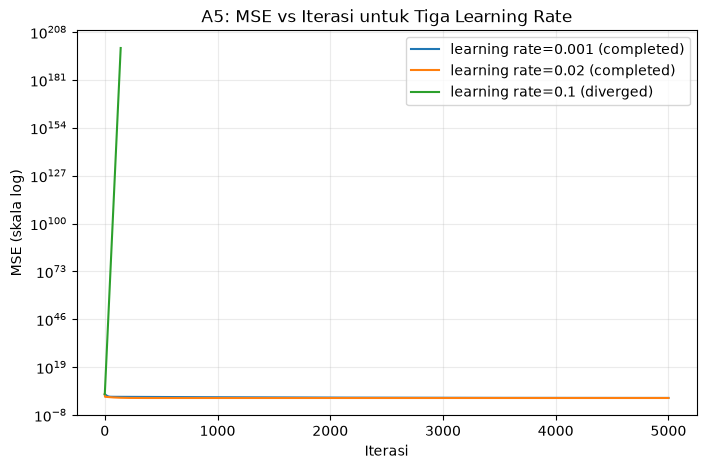

lr=0.001: status=completed, iterasi selesai=5000/5000, intercept=25.9753, koefisien=9.38133, MSE terakhir=42.362
lr=0.02: status=completed, iterasi selesai=5000/5000, intercept=29.1456, koefisien=8.85599, MSE terakhir=40.1528
lr=0.1: status=diverged, iterasi selesai=141/5000, intercept=9.5257e+97, koefisien=5.74852e+98, MSE terakhir=1.00593e+199
  Eksperimen dihentikan aman: magnitudo melampaui batas numerik 1e+100; parameter yang dilaporkan adalah nilai finite terakhir.
MSE optimum Normal Equation pada train=40.1528; ambang 1% dari perbaikan awal=95.7558.
Iterasi untuk mencapai ambang (None berarti belum tercapai): {0.001: 1232, 0.02: 62, 0.1: None}
Interpretasi lr=0.001: mencapai ambang dalam 1232 iterasi; bandingkan angka ini untuk melihat laju konvergensi relatif.
Interpretasi lr=0.02: mencapai ambang dalam 62 iterasi; bandingkan angka ini untuk melihat laju konvergensi relatif.
Interpretasi lr=0.1: divergen; kegagalan dipertahankan dan dihentikan sebelum merusak kernel.


In [5]:
def fit_linear_gd_guarded(X, y, learning_rate, n_iterations=5000, divergence_limit=1e100):
    X = np.asarray(X, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float)
    intercept = 0.0
    coefficient = 0.0
    residual = intercept + coefficient * X - y
    loss_history = [float(np.mean(residual ** 2))]
    status = "completed"
    stop_reason = ""
    completed_iterations = 0

    for iteration in range(1, n_iterations + 1):
        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                residual = intercept + coefficient * X - y
                grad_intercept = 2 * np.mean(residual)
                grad_coefficient = 2 * np.mean(residual * X)
                candidate_intercept = intercept - learning_rate * grad_intercept
                candidate_coefficient = coefficient - learning_rate * grad_coefficient
                candidate_residual = candidate_intercept + candidate_coefficient * X - y
        except FloatingPointError:
            status = "diverged"
            stop_reason = "operasi menghasilkan nilai non-finite (overflow/invalid)"
            break

        candidates = np.array([candidate_intercept, candidate_coefficient, *candidate_residual])
        if not np.all(np.isfinite(candidates)):
            status = "diverged"
            stop_reason = "kandidat parameter atau residual non-finite"
            break
        if np.max(np.abs(candidates)) > divergence_limit:
            status = "diverged"
            stop_reason = f"magnitudo melampaui batas numerik {divergence_limit:.0e}"
            break

        candidate_loss = float(np.mean(candidate_residual ** 2))
        if not np.isfinite(candidate_loss):
            status = "diverged"
            stop_reason = "loss non-finite"
            break

        intercept = float(candidate_intercept)
        coefficient = float(candidate_coefficient)
        loss_history.append(candidate_loss)
        completed_iterations = iteration

    return {
        "intercept": intercept,
        "coefficient": coefficient,
        "loss_history": loss_history,
        "status": status,
        "stop_reason": stop_reason,
        "iterations": completed_iterations,
    }


learning_rates = [0.001, 0.02, 0.1]
gd_results = {
    rate: fit_linear_gd_guarded(X_ads_train, y_ads_train, rate, n_iterations=5000)
    for rate in learning_rates
}
normal_equation_train_mse = float(np.mean((X_ads_train[:, 0] * ads_slope + ads_intercept - y_ads_train) ** 2))

plt.figure(figsize=(8, 5))
for rate, result in gd_results.items():
    history = np.asarray(result["loss_history"])
    plt.semilogy(np.arange(len(history)), np.maximum(history, np.finfo(float).tiny),
                 label=f"learning rate={rate} ({result['status']})")
plt.title("A5: MSE vs Iterasi untuk Tiga Learning Rate")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

for rate, result in gd_results.items():
    print(f"lr={rate}: status={result['status']}, iterasi selesai={result['iterations']}/5000, "
          f"intercept={result['intercept']:.6g}, koefisien={result['coefficient']:.6g}, "
          f"MSE terakhir={result['loss_history'][-1]:.6g}")
    if result["stop_reason"]:
        print(f"  Eksperimen dihentikan aman: {result['stop_reason']}; "
              "parameter yang dilaporkan adalah nilai finite terakhir.")

initial_mse = gd_results[learning_rates[0]]["loss_history"][0]
loss_target = normal_equation_train_mse + 0.01 * max(initial_mse - normal_equation_train_mse, 0)
iterations_to_target = {}
for rate, result in gd_results.items():
    reached = np.flatnonzero(np.asarray(result["loss_history"]) <= loss_target)
    iterations_to_target[rate] = int(reached[0]) if len(reached) else None
print(f"MSE optimum Normal Equation pada train={normal_equation_train_mse:.6g}; "
      f"ambang 1% dari perbaikan awal={loss_target:.6g}.")
print("Iterasi untuk mencapai ambang (None berarti belum tercapai):", iterations_to_target)
for rate, result in gd_results.items():
    if result["status"] == "diverged":
        print(f"Interpretasi lr={rate}: divergen; kegagalan dipertahankan dan dihentikan sebelum merusak kernel.")
    elif iterations_to_target[rate] is None:
        print(f"Interpretasi lr={rate}: belum mencapai ambang konvergensi dalam 5.000 iterasi.")
    else:
        print(f"Interpretasi lr={rate}: mencapai ambang dalam {iterations_to_target[rate]} iterasi; "
              "bandingkan angka ini untuk melihat laju konvergensi relatif.")

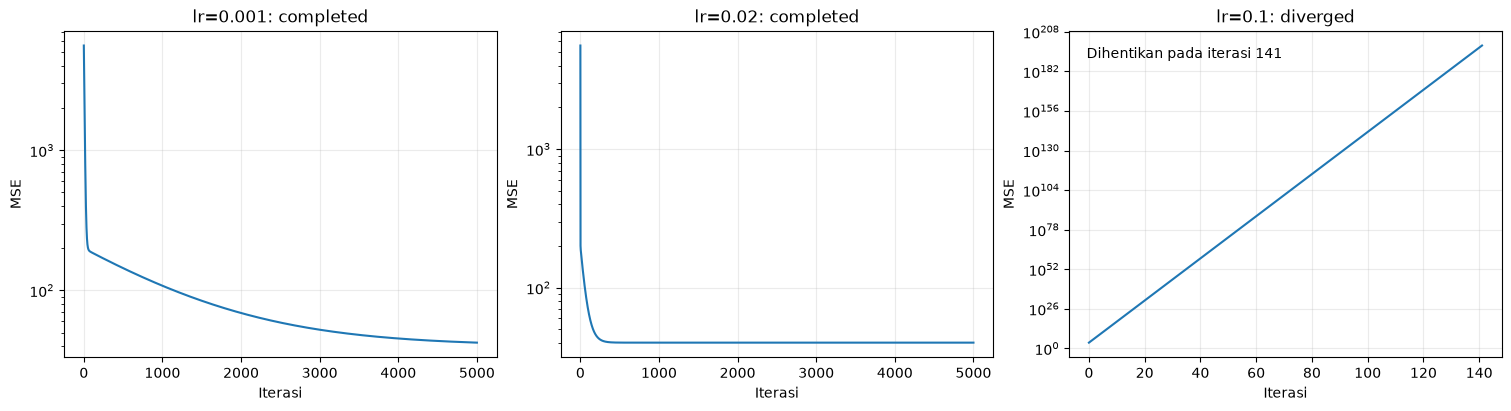

Normal Equation: intercept=29.145637, koefisien=8.855992


,Learning rate,Status,Iterasi,Intercept,Koefisien,Delta intercept vs Normal Equation,Delta koefisien vs Normal Equation
0,0.001,completed,5000,2.597534e+01,9.381333e+00,-3.170299e+00,5.253410e-01
1,0.020,completed,5000,2.914564e+01,8.855992e+00,-2.273737e-13,3.552714e-14
2,0.100,diverged,141,9.525698e+97,5.748516e+98,9.525698e+97,5.748516e+98


In [6]:
# Tampilan per learning rate menjaga kurva konvergen tetap terbaca tanpa membuang loss divergen.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for axis, rate in zip(axes, learning_rates):
    result = gd_results[rate]
    history = np.asarray(result["loss_history"])
    axis.semilogy(np.arange(len(history)), np.maximum(history, np.finfo(float).tiny))
    axis.set_title(f"lr={rate}: {result['status']}")
    axis.set_xlabel("Iterasi")
    axis.set_ylabel("MSE")
    axis.grid(alpha=0.25)
    if result["status"] == "diverged":
        axis.text(0.04, 0.95, f"Dihentikan pada iterasi {result['iterations']}",
                  transform=axis.transAxes, va="top")
plt.show()

comparison_rows = []
for rate, result in gd_results.items():
    comparison_rows.append({
        "Learning rate": rate,
        "Status": result["status"],
        "Iterasi": result["iterations"],
        "Intercept": result["intercept"],
        "Koefisien": result["coefficient"],
        "Delta intercept vs Normal Equation": result["intercept"] - ads_intercept,
        "Delta koefisien vs Normal Equation": result["coefficient"] - ads_slope,
    })
print(f"Normal Equation: intercept={ads_intercept:.6f}, koefisien={ads_slope:.6f}")
display(pd.DataFrame(comparison_rows))

### Animasi Proses Gradient Descent

Kurva MSE bergerak mengikuti iterasi untuk membandingkan tiga ukuran langkah. Setiap panel memakai skala sendiri agar proses konvergen maupun divergen tetap terlihat.

In [7]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

animation_frame_count = 100
fig, axes = plt.subplots(1, len(learning_rates), figsize=(15, 4), constrained_layout=True)
animation_lines = []
animation_histories = []

for axis, rate in zip(axes, learning_rates):
    history = np.maximum(
        np.asarray(gd_results[rate]["loss_history"], dtype=float),
        np.finfo(float).tiny,
    )
    (line,) = axis.semilogy([], [], linewidth=2)
    axis.set_xlim(0, max(1, len(history) - 1))
    lower = max(float(history.min()) * 0.8, np.finfo(float).tiny)
    upper = max(float(history.max()) * 1.2, lower * 10)
    axis.set_ylim(lower, upper)
    axis.set_xlabel("Iterasi")
    axis.set_ylabel("MSE")
    axis.grid(alpha=0.25)
    animation_lines.append(line)
    animation_histories.append(history)


def update_gradient_descent_animation(frame):
    progress = frame / animation_frame_count
    for axis, line, history, rate in zip(
        axes, animation_lines, animation_histories, learning_rates
    ):
        visible_count = max(1, int(round(progress * (len(history) - 1))) + 1)
        visible_count = min(visible_count, len(history))
        line.set_data(np.arange(visible_count), history[:visible_count])
        iteration = visible_count - 1
        status = gd_results[rate]["status"]
        axis.set_title(f"lr={rate} ({status}) | iterasi {iteration}")
    return animation_lines


fig.suptitle("Animasi: MSE Gradient Descent")
gd_animation = FuncAnimation(
    fig,
    update_gradient_descent_animation,
    frames=animation_frame_count + 1,
    interval=80,
    repeat=True,
    blit=False,
)
plt.close(fig)
HTML(gd_animation.to_jshtml(default_mode="loop"))

## 6. Mencoba Batas Peluang Spam

Model menandai email sebagai spam jika peluangnya melewati batas (`threshold`). Kita membandingkan batas `0.3`, `0.5`, dan `0.7`. Batas yang lebih tinggi berarti model perlu lebih yakin sebelum menandai spam; akibatnya, lebih sedikit email dapat masuk folder spam, tetapi sebagian spam mungkin lolos.

Pada data uji kali ini, ketiga batas menghasilkan label yang sama. Kita tetap memakai `0.5` sebagai pilihan awal karena tugas tidak memberi aturan bahwa salah satu jenis kesalahan lebih mahal, dan tidak ada kumpulan data validasi terpisah untuk memilih batas terbaik.

In [8]:
threshold_results = {}
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    predictions = (custom_email_probability >= threshold).astype(int)
    confusion, scores = classification_metrics(y_email_test, predictions)
    tn, fp = confusion[0]
    fn, tp = confusion[1]
    threshold_results[threshold] = {
        "predictions": predictions,
        "confusion": confusion,
        "scores": scores,
    }
    threshold_rows.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        **scores,
    })

threshold_table = pd.DataFrame(threshold_rows).set_index("Threshold")
print("Confusion matrix memakai urutan [[TN, FP], [FN, TP]].")
display(threshold_table)
print("Threshold awal yang dipilih: 0.5, karena tidak ada dasar biaya kesalahan atau validasi "
      "terpisah untuk memilih threshold lain. Threshold lebih tinggi mensyaratkan keyakinan "
      "lebih besar sebelum memberi label Spam; konsekuensi precision/recall terlihat pada tabel.")

Confusion matrix memakai urutan [[TN, FP], [FN, TP]].


,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Threshold,,,,,,,,
0.3,6,1,0,8,0.933333,0.888889,1.0,0.941176
0.5,6,1,0,8,0.933333,0.888889,1.0,0.941176
0.7,6,1,0,8,0.933333,0.888889,1.0,0.941176


Threshold awal yang dipilih: 0.5, karena tidak ada dasar biaya kesalahan atau validasi terpisah untuk memilih threshold lain. Threshold lebih tinggi mensyaratkan keyakinan lebih besar sebelum memberi label Spam; konsekuensi precision/recall terlihat pada tabel.


In [9]:
threshold_prediction_arrays = [threshold_results[value]["predictions"] for value in [0.3, 0.5, 0.7]]
if all(np.array_equal(threshold_prediction_arrays[0], values)
       for values in threshold_prediction_arrays[1:]):
    print("Interpretasi B5: pada split test ini, threshold 0.3, 0.5, dan 0.7 menghasilkan "
          "kelas yang sama, sehingga precision dan recall tidak berubah (precision="
          f"{threshold_results[0.5]['scores']['Precision']:.3f}, recall="
          f"{threshold_results[0.5]['scores']['Recall']:.3f}). Secara umum, menaikkan "
          "threshold cenderung mengurangi prediksi Spam dan recall; precision dapat naik "
          "atau turun bergantung pada contoh yang berubah kelas.")
else:
    print("Interpretasi B5: perubahan metrik aktual saat threshold dinaikkan dari 0.3 ke 0.7: "
          f"precision {threshold_results[0.3]['scores']['Precision']:.3f} -> "
          f"{threshold_results[0.7]['scores']['Precision']:.3f}; recall "
          f"{threshold_results[0.3]['scores']['Recall']:.3f} -> "
          f"{threshold_results[0.7]['scores']['Recall']:.3f}. Secara umum, threshold lebih "
          "tinggi mengurangi prediksi Spam dan cenderung menurunkan recall; arah perubahan "
          "precision bergantung pada contoh yang berubah kelas.")
print("Threshold awal tetap 0.5: tidak ada biaya kesalahan atau validation set terpisah "
      "untuk membenarkan pilihan lain.")

Interpretasi B5: pada split test ini, threshold 0.3, 0.5, dan 0.7 menghasilkan kelas yang sama, sehingga precision dan recall tidak berubah (precision=0.889, recall=1.000). Secara umum, menaikkan threshold cenderung mengurangi prediksi Spam dan recall; precision dapat naik atau turun bergantung pada contoh yang berubah kelas.
Threshold awal tetap 0.5: tidak ada biaya kesalahan atau validation set terpisah untuk membenarkan pilihan lain.


## 7. Memahami Hasil dan Contoh Perkiraan

### Perkiraan penjualan

MAE, MSE, RMSE, dan $R^2$ adalah cara berbeda untuk melihat jarak antara perkiraan dan angka sebenarnya. RMSE punya satuan yang sama dengan penjualan, yaitu juta rupiah; pada data uji, rata-rata kesalahan model sekitar Rp4,751 juta. Nilai $R^2$ sebesar 0,9728 berarti garis mengikuti pola 8 catatan uji dengan baik, tetapi belum menjamin hasil yang sama pada bulan lain.

### Penilaian email

Confusion matrix merangkum hasil dengan urutan `[[TN, FP], [FN, TP]]`:
- `TN`: email biasa dikenali dengan benar.
- `FP`: email biasa keliru ditandai sebagai spam.
- `FN`: spam keliru dianggap email biasa.
- `TP`: spam dikenali dengan benar.

Accuracy adalah bagian semua email yang dinilai benar. Precision menjawab: dari email yang ditandai spam, berapa yang memang spam? Recall menjawab: dari semua spam, berapa yang ditemukan? F1 merangkum precision dan recall dalam satu angka.

### Perkiraan lain

Model memperkirakan penjualan untuk biaya iklan 4.5, 7, dan 12 juta rupiah. Angka 12 berada di luar jangkauan data, sehingga hasilnya lebih tidak pasti. Grafik email menunjukkan bagaimana peluang spam berubah menurut jumlah tautan dan kata promosi; tanda silang menandai email uji yang salah dinilai. Peluang untuk E1-E4 adalah perkiraan, bukan kepastian.

In [10]:
# A4: metrik dihitung sendiri dengan NumPy untuk train dan test.
ads_train_pred = ads_intercept + X_ads_train[:, 0] * ads_slope
ads_test_pred = ads_intercept + X_ads_test[:, 0] * ads_slope
ads_metrics_table = pd.DataFrame(
    [regression_metrics(y_ads_train, ads_train_pred),
     regression_metrics(y_ads_test, ads_test_pred)],
    index=["Train", "Test"],
)
print("A4: MAE, MSE, RMSE, dan R2")
display(ads_metrics_table)
print(f"Interpretasi test: RMSE={ads_metrics_table.loc['Test', 'RMSE']:.3f} juta Rp "
      f"dan R2={ads_metrics_table.loc['Test', 'R2']:.4f}. Pada split ini model mengikuti "
      "pola linear dengan baik, tetapi ukuran test hanya 8 observasi dan tidak membuktikan "
      "hubungan sebab-akibat atau kinerja di luar rentang data.")

A4: MAE, MSE, RMSE, dan R2


,MAE,MSE,RMSE,R2
Train,4.656899,40.152778,6.336622,0.925261
Test,4.477319,22.568865,4.750670,0.972767


Interpretasi test: RMSE=4.751 juta Rp dan R2=0.9728. Pada split ini model mengikuti pola linear dengan baik, tetapi ukuran test hanya 8 observasi dan tidak membuktikan hubungan sebab-akibat atau kinerja di luar rentang data.


In [11]:
# B3: evaluasi email uji pada batas peluang 0.5.
email_test_pred = threshold_results[0.5]["predictions"]
email_confusion, email_scores = classification_metrics(y_email_test, email_test_pred)
print("Tabel membandingkan label sebenarnya (baris) dengan label perkiraan (kolom).")
display(pd.DataFrame(email_confusion, index=["Sebenarnya bukan spam", "Sebenarnya spam"],
                     columns=["Perkiraan bukan spam", "Perkiraan spam"]))
display(pd.DataFrame([email_scores], index=["Email uji, batas 0.5"]))
fp_count = int(email_confusion[0, 1])
fn_count = int(email_confusion[1, 0])
print(f"Email biasa yang keliru ditandai spam: {fp_count}; spam yang terlewat: {fn_count}.")
print("Email biasa yang masuk folder spam bisa membuat pesan penting terlewat. Spam yang "
      "lolos tetap terlihat di inbox. Dampak kesalahan bergantung pada cara folder spam "
      "ditangani; tugas ini tidak menentukan mana yang lebih merugikan.")

Tabel membandingkan label sebenarnya (baris) dengan label perkiraan (kolom).


,Perkiraan bukan spam,Perkiraan spam
Sebenarnya bukan spam,6,1
Sebenarnya spam,0,8


,Accuracy,Precision,Recall,F1
"Email uji, batas 0.5",0.933333,0.888889,1.0,0.941176


Email biasa yang keliru ditandai spam: 1; spam yang terlewat: 0.
Email biasa yang masuk folder spam bisa membuat pesan penting terlewat. Spam yang lolos tetap terlihat di inbox. Dampak kesalahan bergantung pada cara folder spam ditangani; tugas ini tidak menentukan mana yang lebih merugikan.


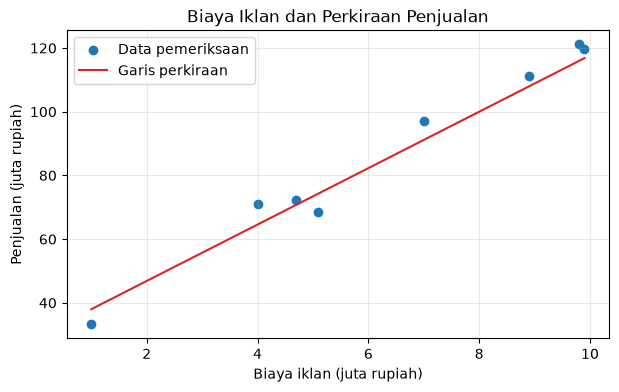

,Biaya iklan (juta rupiah),Perkiraan penjualan (juta rupiah)
0,4.5,68.997602
1,7.0,91.137582
2,12.0,135.417543


Biaya iklan pada data berada antara 0.8 hingga 9.9 juta rupiah. Nilai 12 juta berada di luar rentang itu, sehingga perkiraannya lebih tidak pasti.


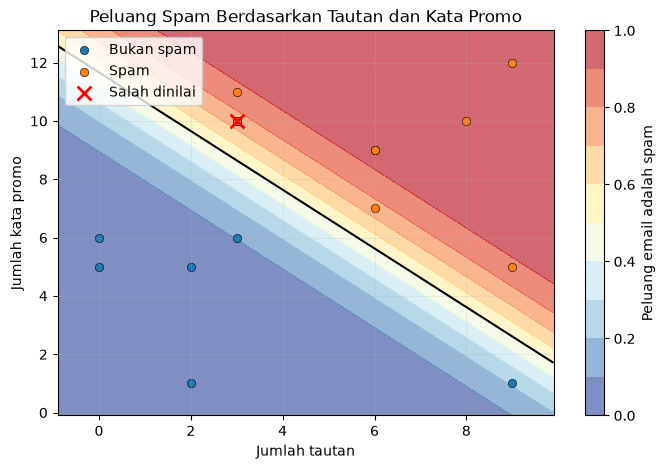

Garis hitam menunjukkan batas peluang 50%: model memberi label spam di satu sisi dan bukan spam di sisi lainnya.
Persamaan batas: KataPromo = -(-9.446247 + 0.814785*JumlahLink)/0.809802
Email uji yang salah dinilai: 1


,Jumlah tautan,Kata promo,Label sebenarnya (1=spam),Label perkiraan (1=spam),Peluang spam
0,3,10,0,1,0.749534


In [12]:
# A6: visualisasi data uji, garis hasil hitung langsung, dan perkiraan.
line_x = np.linspace(float(X_ads_test.min()), float(X_ads_test.max()), 100)
plt.figure(figsize=(7, 4))
plt.scatter(X_ads_test[:, 0], y_ads_test, label="Data pemeriksaan")
plt.plot(line_x, ads_intercept + ads_slope * line_x, color="tab:red", label="Garis perkiraan")
plt.title("Biaya Iklan dan Perkiraan Penjualan")
plt.xlabel("Biaya iklan (juta rupiah)")
plt.ylabel("Penjualan (juta rupiah)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

ad_spend_examples = np.array([4.5, 7.0, 12.0])
ad_sales_predictions = ads_intercept + ads_slope * ad_spend_examples
ad_prediction_table = pd.DataFrame({
    "Biaya iklan (juta rupiah)": ad_spend_examples,
    "Perkiraan penjualan (juta rupiah)": ad_sales_predictions,
})
display(ad_prediction_table)
print(f"Biaya iklan pada data berada antara {X_ads.min():.1f} hingga {X_ads.max():.1f} juta rupiah. "
      "Nilai 12 juta berada di luar rentang itu, sehingga perkiraannya lebih tidak pasti.")

# B4: peta peluang spam, garis peluang 50%, dan email uji yang salah dinilai.
def predict_email_probability(X_raw):
    return sigmoid(((np.asarray(X_raw, dtype=float) - email_mean) / email_scale) @ logistic_weights + logistic_bias)

x1_min, x1_max = X_email_test[:, 0].min(), X_email_test[:, 0].max()
x2_min, x2_max = X_email_test[:, 1].min(), X_email_test[:, 1].max()
padding_x1 = max((x1_max - x1_min) * 0.1, 0.5)
padding_x2 = max((x2_max - x2_min) * 0.1, 0.5)
grid_x1, grid_x2 = np.meshgrid(
    np.linspace(x1_min - padding_x1, x1_max + padding_x1, 160),
    np.linspace(x2_min - padding_x2, x2_max + padding_x2, 160),
)
grid_features = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
grid_probabilities = predict_email_probability(grid_features).reshape(grid_x1.shape)

plt.figure(figsize=(8, 5))
probability_plot = plt.contourf(grid_x1, grid_x2, grid_probabilities,
                                levels=np.linspace(0, 1, 11), cmap="RdYlBu_r", alpha=0.65)
plt.colorbar(probability_plot, label="Peluang email adalah spam")
for label, name, color in [(0, "Bukan spam", "tab:blue"), (1, "Spam", "tab:orange")]:
    mask = y_email_test == label
    plt.scatter(X_email_test[mask, 0], X_email_test[mask, 1], label=name,
                color=color, edgecolor="black", linewidth=0.4)
if np.min(grid_probabilities) <= 0.5 <= np.max(grid_probabilities):
    plt.contour(grid_x1, grid_x2, grid_probabilities, levels=[0.5], colors="black", linewidths=1.5)
wrong_mask = email_test_pred != y_email_test
plt.scatter(X_email_test[wrong_mask, 0], X_email_test[wrong_mask, 1], marker="x",
            s=100, linewidths=2, color="red", label="Salah dinilai")
plt.title("Peluang Spam Berdasarkan Tautan dan Kata Promo")
plt.xlabel("Jumlah tautan")
plt.ylabel("Jumlah kata promo")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print("Garis hitam menunjukkan batas peluang 50%: model memberi label spam di satu sisi "
      "dan bukan spam di sisi lainnya.")
print(f"Persamaan batas: KataPromo = -({logistic_intercept:.6f} + "
      f"{logistic_coefficients[0]:.6f}*JumlahLink)/{logistic_coefficients[1]:.6f}")
misclassified_emails = pd.DataFrame({
    "Jumlah tautan": X_email_test[wrong_mask, 0].astype(int),
    "Kata promo": X_email_test[wrong_mask, 1].astype(int),
    "Label sebenarnya (1=spam)": y_email_test[wrong_mask],
    "Label perkiraan (1=spam)": email_test_pred[wrong_mask],
    "Peluang spam": custom_email_probability[wrong_mask],
})
print(f"Email uji yang salah dinilai: {int(wrong_mask.sum())}")
display(misclassified_emails)

In [13]:
# B6: skor probabilitas dan kelas email baru pada threshold pilihan 0.5.
new_emails = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11],
})
new_email_features = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_email_probabilities = predict_email_probability(new_email_features)
new_email_predictions = (new_email_probabilities >= 0.5).astype(int)
new_emails["P(Spam)"] = new_email_probabilities
new_emails["Prediksi"] = np.where(new_email_predictions == 1, "Spam", "Bukan Spam")
print("B6: probabilitas adalah skor model, bukan kepastian bahwa email benar-benar spam.")
display(new_emails)

B6: probabilitas adalah skor model, bukan kepastian bahwa email benar-benar spam.


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.000900,Bukan Spam
1,E2,5,6,0.374371,Bukan Spam
2,E3,9,10,0.997490,Spam
3,E4,2,11,0.748597,Spam


## 8. Memastikan File Data Ditemukan

Notebook mencari `Ads_Data.csv` dan `Email_Data.csv` di folder notebook atau folder induknya. Jadi, tidak perlu menulis alamat folder khusus komputer. Untuk menjalankan di komputer lain, letakkan kedua CSV bersama notebook.

In [14]:
for csv_name in ["Ads_Data.csv", "Email_Data.csv"]:
    assert (data_dir / csv_name).is_file()
assert len(ads_data) == 40 and len(email_data) == 60
assert not ads_data.isna().any().any() and not email_data.isna().any().any()
print("Audit dataset lulus: kedua CSV ditemukan melalui pencarian relatif, "
      "40 baris iklan, 60 baris email, tanpa nilai kosong.")
print("Path absolut tidak diperlukan di kode; letakkan CSV berdampingan dengan notebook.")

Audit dataset lulus: kedua CSV ditemukan melalui pencarian relatif, 40 baris iklan, 60 baris email, tanpa nilai kosong.
Path absolut tidak diperlukan di kode; letakkan CSV berdampingan dengan notebook.


## 9. Ringkasan untuk README

Sel berikut mencetak angka dari perhitungan notebook ini. README memakai angka tersebut agar ringkasan dan hasil yang terlihat di notebook tetap sama.

In [15]:
final_summary = {
    "NIM": "241011402714",
    "Kelas": "Reg B",
    "Jumlah data iklan": len(ads_data),
    "Jumlah data email": len(email_data),
    "Intercept regresi": ads_intercept,
    "Slope regresi": ads_slope,
    "R2 test regresi": ads_metrics_table.loc["Test", "R2"],
    "RMSE test regresi": ads_metrics_table.loc["Test", "RMSE"],
    "Accuracy test logistic (threshold 0.5)": email_scores["Accuracy"],
    "Precision test logistic (threshold 0.5)": email_scores["Precision"],
    "Recall test logistic (threshold 0.5)": email_scores["Recall"],
    "F1 test logistic (threshold 0.5)": email_scores["F1"],
    "TN": int(email_confusion[0, 0]),
    "FP": int(email_confusion[0, 1]),
    "FN": int(email_confusion[1, 0]),
    "TP": int(email_confusion[1, 1]),
}
print("Ringkasan aktual untuk README (dihasilkan dari eksekusi notebook ini):")
for name, value in final_summary.items():
    print(f"{name}: {value}")
print("\nGradient Descent:")
for rate, result in gd_results.items():
    print(f"lr={rate}: {result['status']}, {result['iterations']} iterasi, "
          f"intercept={result['intercept']:.6g}, koefisien={result['coefficient']:.6g}")
print("\nPrediksi email contoh:")
display(new_emails)

Ringkasan aktual untuk README (dihasilkan dari eksekusi notebook ini):
NIM: 241011402714
Kelas: Reg B
Jumlah data iklan: 40
Jumlah data email: 60
Intercept regresi: 29.145637422575597
Slope regresi: 8.855992111183014
R2 test regresi: 0.9727674141276559
RMSE test regresi: 4.750669965771598
Accuracy test logistic (threshold 0.5): 0.9333333333333333
Precision test logistic (threshold 0.5): 0.8888888888888888
Recall test logistic (threshold 0.5): 1.0
F1 test logistic (threshold 0.5): 0.9411764705882353
TN: 6
FP: 1
FN: 0
TP: 8

Gradient Descent:
lr=0.001: completed, 5000 iterasi, intercept=25.9753, koefisien=9.38133
lr=0.02: completed, 5000 iterasi, intercept=29.1456, koefisien=8.85599
lr=0.1: diverged, 141 iterasi, intercept=9.5257e+97, koefisien=5.74852e+98

Prediksi email contoh:


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.000900,Bukan Spam
1,E2,5,6,0.374371,Bukan Spam
2,E3,9,10,0.997490,Spam
3,E4,2,11,0.748597,Spam


## 10. Pemeriksaan Terakhir

Jalankan semua sel dari atas ke bawah. Pemeriksaan terakhir memastikan tabel, peluang email, tiga batas, dan hasil Gradient Descent tersedia. Pesan bahwa `learning rate 0.1` divergen adalah hasil percobaan yang memang diharapkan, bukan error program.

In [16]:
assert set(gd_results) == {0.001, 0.02, 0.1}
assert gd_results[0.001]["status"] == "completed"
assert gd_results[0.02]["status"] == "completed"
assert gd_results[0.1]["status"] == "diverged"
assert all(np.all(np.isfinite(result["loss_history"])) for result in gd_results.values())
assert all(np.isfinite(result["intercept"]) and np.isfinite(result["coefficient"])
           for result in gd_results.values())
assert set(threshold_results) == {0.3, 0.5, 0.7}
assert int(email_confusion.sum()) == len(y_email_test)
assert np.isclose(email_scores["Accuracy"],
                   (email_confusion[0, 0] + email_confusion[1, 1]) / email_confusion.sum())
assert len(new_emails) == 4 and len(misclassified_emails) == int(wrong_mask.sum())
assert np.isfinite(ads_metrics_table.to_numpy()).all()
print("Pemeriksaan akhir lulus: hasil model, tabel, contoh email, dan penanganan "
      "percobaan yang gagal sudah konsisten.")

Pemeriksaan akhir lulus: hasil model, tabel, contoh email, dan penanganan percobaan yang gagal sudah konsisten.
